### Simple Visualisations

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

#### Load data

In [17]:
event_t = np.random.choice(['shoot', 'goal'], size=1000, p =[0.7, 0.3])
shoot_type = np.random.choice(['a', 'b', 'c', 'd'], size =1000, p=[0.4, 0.3, 0.2, 0.1])
home_team = np.array(["home_team"]*1000)
team_attack = np.random.choice(['home_team', 'away_team'], size = 1000)
home_rink = np.random.choice(['right', 'left'], 1000)
x = np.random.uniform(low = -100, high = 100, size=1000)
y = np.random.uniform(low = -42.5, high = 42.5, size=1000)
data_game = {'Event_Type': event_t, 'Shoot_Type': shoot_type, 'Home_Team': home_team, 'Team_Attack': team_attack, 'Home_Rink': home_rink, 'X_Coordinate': x, 'Y_Coordinate':y}
df = pd.DataFrame(data_game)
df

,Event_Type,Shoot_Type,Home_Team,Team_Attack,Home_Rink,X_Coordinate,Y_Coordinate
0,shoot,a,home_team,home_team,right,87.721408,-18.340236
1,shoot,b,home_team,away_team,right,11.263147,-11.636738
2,goal,b,home_team,home_team,left,50.497751,28.032078
3,shoot,c,home_team,away_team,left,68.902125,15.438124
4,goal,b,home_team,away_team,right,4.078796,5.692313
...,...,...,...,...,...,...,...
995,shoot,a,home_team,away_team,right,5.463158,-36.965405
996,shoot,b,home_team,home_team,left,-69.430715,-20.606590
997,goal,a,home_team,home_team,right,74.616552,32.283574
998,shoot,b,home_team,home_team,left,40.788308,-21.916110


#### 1) Shot type comparaison

/Users/nassimwalha/opt/miniconda3/envs/project/lib/python3.10/site-packages/seaborn/distributions.py:269: FutureWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  baselines.iloc[:, cols] = (curves


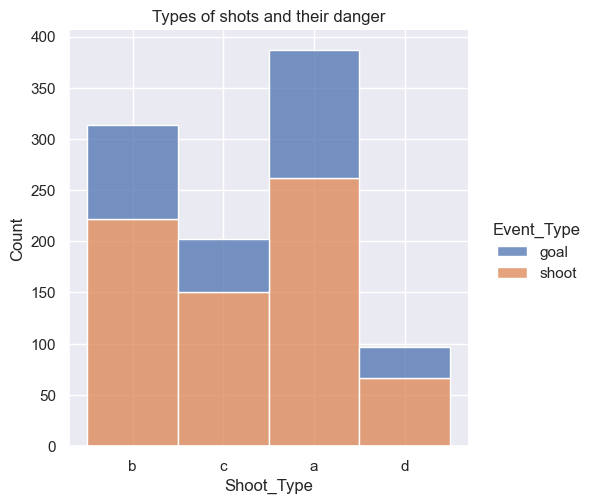

In [12]:
sns.set_theme()
g = sns.displot(df, x="Shoot_Type", hue="Event_Type", multiple="stack", hue_order=['goal', 'shoot'])
plt.title("Types of shots and their danger")
plt.show(g)

#### 2) Change of a goal depending on distance

In [21]:
GOALS = {"right": (89,0),"left": (-89,0)}
def calc_distance(equipe, home, home_current_rinkside, x, y):
    is_home = equipe == home
    if home_current_rinkside == np.nan:
        opponent_goal = "right" if x>=0 else "left"
    else:
        opponent_goal = "right" if (is_home and home_current_rinkside=="left") \
                               or (not is_home and home_current_rinkside=="right") else "left"
    opponent_goal_coordinates = GOALS[opponent_goal]
    return np.sqrt((x-opponent_goal_coordinates[0])**2+(y-opponent_goal_coordinates[1])**2)

In [22]:
df['Distance']=df.apply(lambda x: calc_distance(x['Team_Attack'],x['Home_Team'],x['Home_Rink'],x['X_Coordinate'], x['Y_Coordinate']), axis=1)

In [24]:
WIDTH = 5

In [27]:
df['Distance_bin']=df.Distance.map(lambda x: int(np.floor(x/WIDTH)*WIDTH))

In [44]:
def calculate_probability(event_types):
    counts = event_types.value_counts(normalize=True)
    if 'goal' in counts:
        return counts['goal']
    return 0.0

In [46]:
df.groupby(by='Distance_bin').agg(goal_probability=pd.NamedAgg(column="Event_Type", aggfunc= calculate_probability))

,goal_probability
Distance_bin,
0,0.000000
5,0.357143
10,0.166667
15,0.320000
20,0.266667
25,0.305556
30,0.405405
35,0.200000
40,0.297872
